<a href="https://colab.research.google.com/github/MNawfal24/MachineLearning/blob/main/Minggu11/MNawfalMA_JS11_P01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# Import library
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns

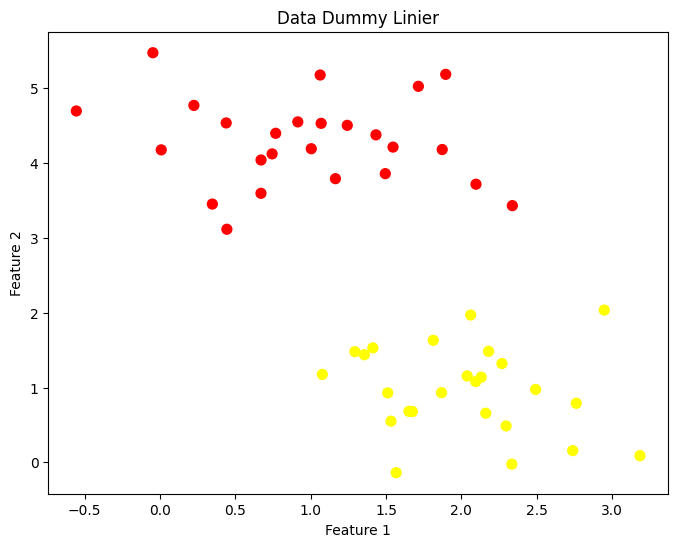

In [3]:
from sklearn.datasets import make_blobs

# Create dummy data with 2 clusters
X, y = make_blobs(n_samples=50, centers=2,
                  random_state=0, cluster_std=0.60)

# Visualize the data
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('Data Dummy Linier')
plt.show()

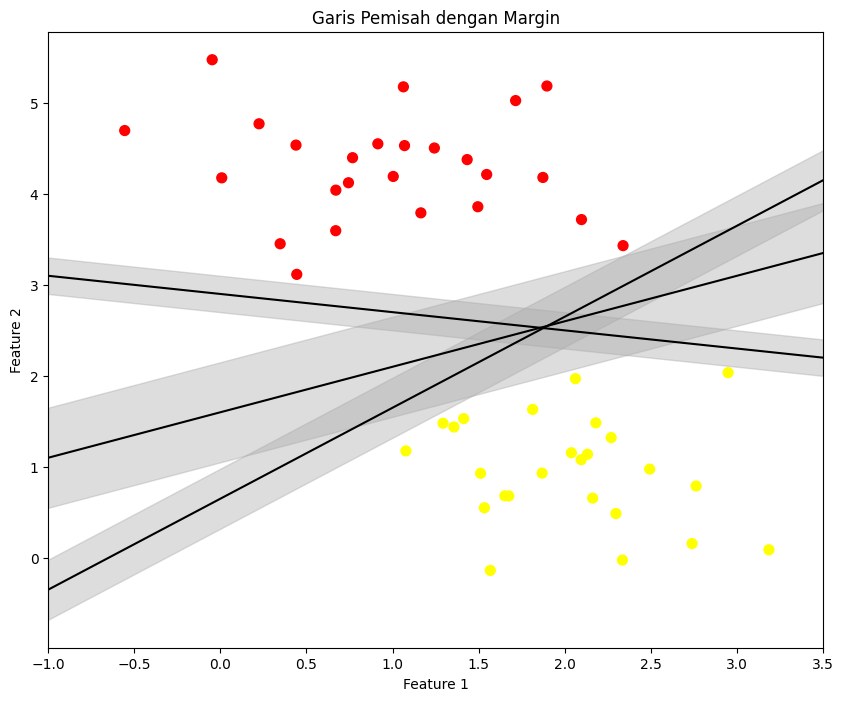

In [4]:
# Illustrate possible separating lines
xfit = np.linspace(-1, 3.5)

plt.figure(figsize=(10, 8))
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

# Multiple possible separating lines
for m, b, d in [(1, 0.65, 0.33), (0.5, 1.6, 0.55), (-0.2, 2.9, 0.2)]:
    yfit = m * xfit + b
    plt.plot(xfit, yfit, '-k')
    plt.fill_between(xfit, yfit - d, yfit + d, edgecolor='none',
                     color='#AAAAAA', alpha=0.4)

plt.xlim(-1, 3.5)
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('Garis Pemisah dengan Margin')
plt.show()

In [6]:
from sklearn.svm import SVC

# Fit SVM model dengan kernel linear
model = SVC(kernel='linear', C=1E10)
model.fit(X, y)

print('Model fitted successfully!')
print(f'Number of support vectors: {len(model.support_vectors_)}')

Model fitted successfully!
Number of support vectors: 3


In [7]:
# Create function to visualize SVM decision function
def plot_svc_decision_function(model, ax=None, plot_support=True):
    if ax is None:
        ax = plt.gca()

    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # Create grid for model evaluation
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)

    # Plot decision boundary and margin
    ax.contour(X, Y, P, colors='k',
               levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])

    # Plot support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=300, linewidth=1.5, facecolors='none', edgecolors='black');

    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

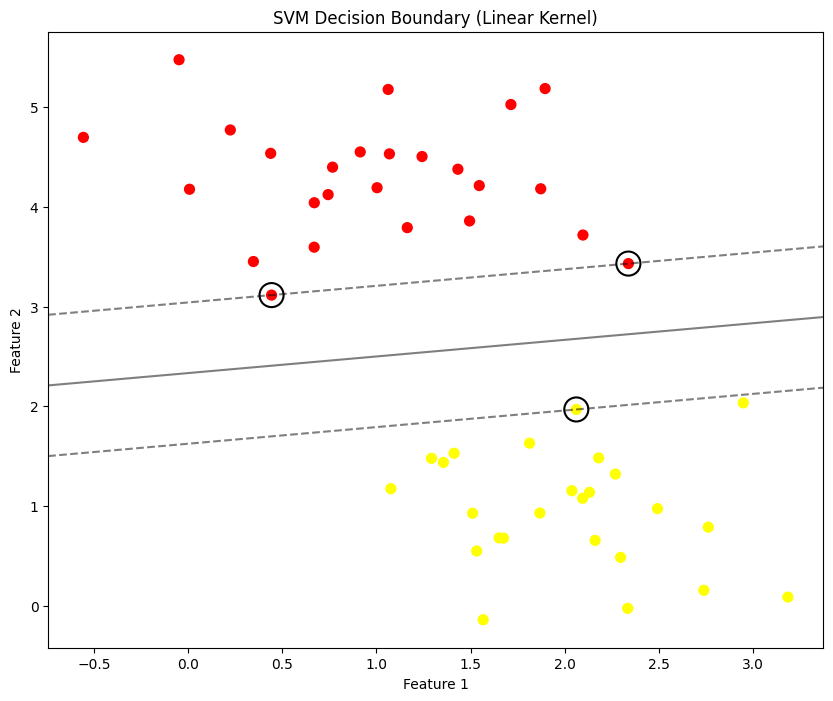

In [8]:
# Plot the result
plt.figure(figsize=(10, 8))
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(model)
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('SVM Decision Boundary (Linear Kernel)')
plt.show()

In [9]:
# Show support vectors
print('Support Vectors:')
print(model.support_vectors_)
print(f'\nIndices of support vectors: {model.support_}')

Support Vectors:
[[0.44359863 3.11530945]
 [2.33812285 3.43116792]
 [2.06156753 1.96918596]]

Indices of support vectors: [18 25  7]


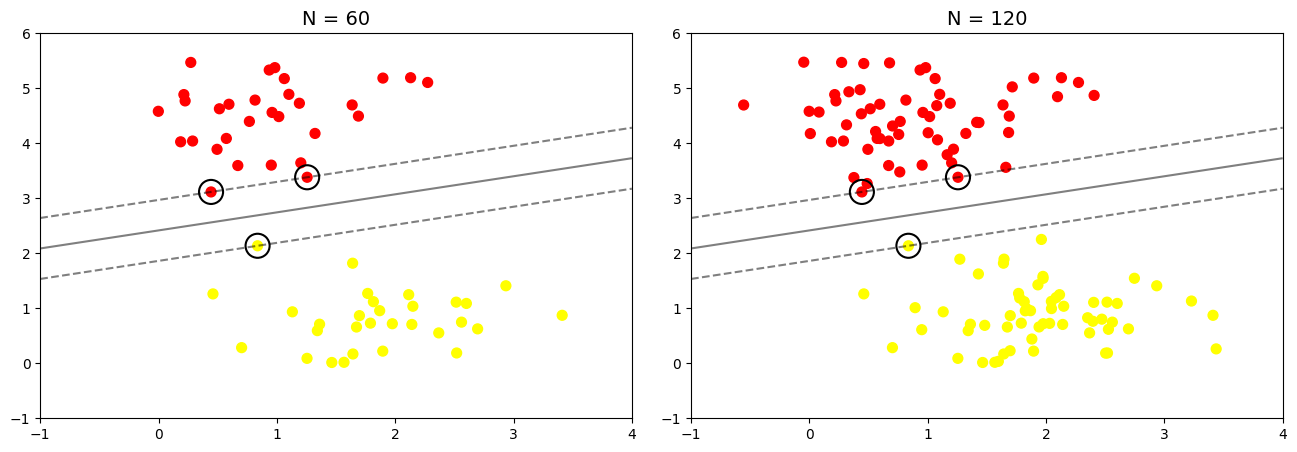

In [10]:
# Function to plot SVM with different data sizes
def plot_svm(N=10, ax=None):
    X_temp, y_temp = make_blobs(n_samples=200, centers=2,
                                 random_state=0, cluster_std=0.60)
    X_subset = X_temp[:N]
    y_subset = y_temp[:N]

    model_temp = SVC(kernel='linear', C=1E10)
    model_temp.fit(X_subset, y_subset)

    ax = ax or plt.gca()
    ax.scatter(X_subset[:, 0], X_subset[:, 1], c=y_subset, s=50, cmap='autumn')
    ax.set_xlim(-1, 4)
    ax.set_ylim(-1, 6)
    plot_svc_decision_function(model_temp, ax)

# Compare with 60 and 120 data points
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)

for axi, N in zip(ax, [60, 120]):
    plot_svm(N, axi)
    axi.set_title(f'N = {N}', size=14)

plt.show()